In [4]:
!pip install prophet==1.1.5 cmdstanpy==1.2.3 pandas scikit-learn matplotlib numpy==1.26

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.5/58.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 119.8 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.0 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.0 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.0 which is incompatible.
opencv-contrib-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.0 which is incompatible.
pytensor 2.35.1 requires numpy>=2.0, but you have numpy 1.26.0 which is incompati

In [1]:
import pandas as pd
import numpy as np
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

In [2]:
data = pd.read_excel("/content/Harga Beras Jabar 2013-2024.xlsx")

In [13]:
# Pastikan kolom sesuai format Prophet
df = data.rename(columns={'Date': 'ds', 'Price': 'y'})
df['ds'] = pd.to_datetime(df['ds'])
df = df.dropna(subset=['y'])  # Hapus NA jika ada
df = df.sort_values('ds')
df.head()

,ds,y
0,2013-01-01,8189.06
1,2013-02-01,8426.67
2,2013-03-01,8213.33
3,2013-04-01,7696.25
4,2013-05-01,8242.11


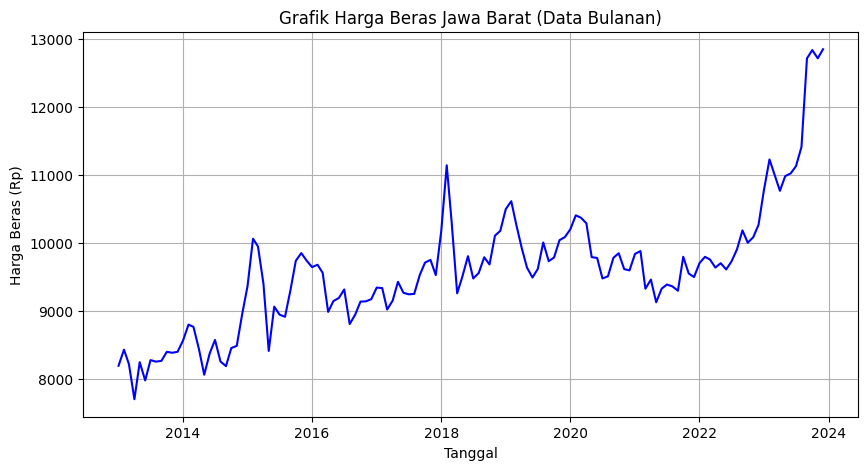

In [14]:
plt.figure(figsize=(10,5))
plt.plot(df['ds'], df['y'], color='blue')
plt.title('Grafik Harga Beras Jawa Barat (Data Bulanan)')
plt.xlabel('Tanggal')
plt.ylabel('Harga Beras (Rp)')
plt.grid(True)
plt.show()

In [4]:
train = df.iloc[:-27]
test = df.iloc[-27:]

In [15]:
model = Prophet(
    yearly_seasonality=True,     # karena data bulanan → ada pola tahunan
    weekly_seasonality=False,    # data bulanan, tidak perlu mingguan
    daily_seasonality=False,
    seasonality_mode='additive', # bisa ubah ke 'multiplicative' jika fluktuasi makin besar
    changepoint_prior_scale=0.05 # mengontrol sensitivitas perubahan tren
)

# Latih model
model.fit(train)

DEBUG:cmdstanpy:input tempfile: /tmp/tmp7h_nvo3h/9mozb1ng.json
DEBUG:cmdstanpy:input tempfile: /tmp/tmp7h_nvo3h/vkhrc5dy.json
DEBUG:cmdstanpy:idx 0
DEBUG:cmdstanpy:running CmdStan, num_threads: None
DEBUG:cmdstanpy:CmdStan args: ['/usr/local/lib/python3.12/dist-packages/prophet/stan_model/prophet_model.bin', 'random', 'seed=54531', 'data', 'file=/tmp/tmp7h_nvo3h/9mozb1ng.json', 'init=/tmp/tmp7h_nvo3h/vkhrc5dy.json', 'output', 'file=/tmp/tmp7h_nvo3h/prophet_modell6v5381v/prophet_model-20251111082403.csv', 'method=optimize', 'algorithm=lbfgs', 'iter=10000']
08:24:03 - cmdstanpy - INFO - Chain [1] start processing
INFO:cmdstanpy:Chain [1] start processing
08:24:03 - cmdstanpy - INFO - Chain [1] done processing
INFO:cmdstanpy:Chain [1] done processing


In [17]:
# Tambahkan 24 bulan ke depan (freq='MS' = month start)
future = model.make_future_dataframe(periods=27, freq='MS')

forecast = model.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()


,ds,yhat,yhat_lower,yhat_upper
127,2023-08-01,8932.041069,8600.503228,9284.423672
128,2023-09-01,8877.602398,8529.534394,9241.451666
129,2023-10-01,8953.104398,8577.520601,9314.795595
130,2023-11-01,9072.899475,8722.040782,9465.204981
131,2023-12-01,9073.936501,8684.314561,9444.346377


/usr/local/lib/python3.12/dist-packages/prophet/plot.py:72: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  fcst_t = fcst['ds'].dt.to_pydatetime()
/usr/local/lib/python3.12/dist-packages/prophet/plot.py:73: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  ax.plot(m.history['ds'].dt.to_pydatetime(), m.history['y'], 'k.',


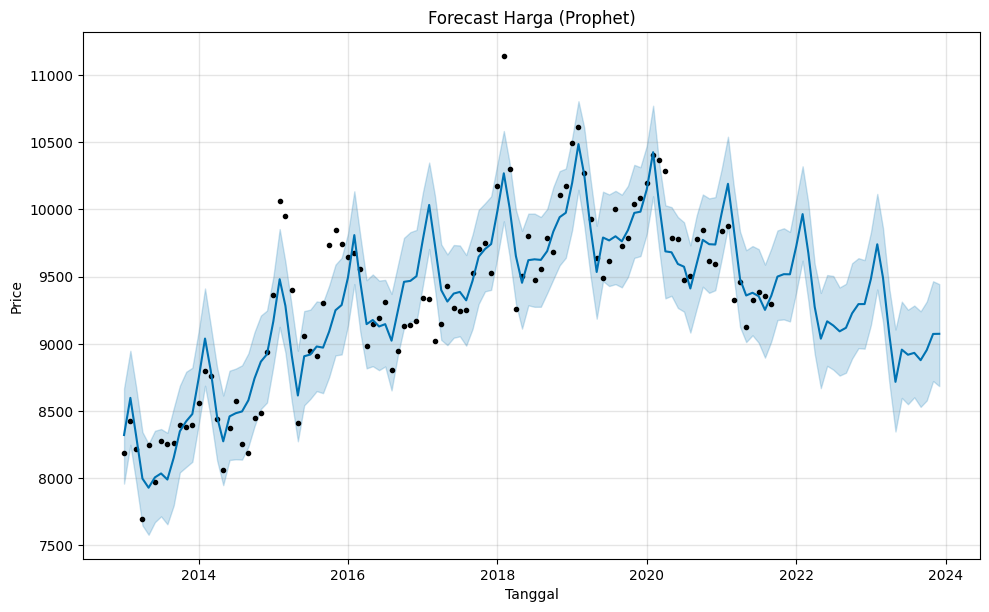

/usr/local/lib/python3.12/dist-packages/prophet/plot.py:228: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  fcst_t = fcst['ds'].dt.to_pydatetime()
/usr/local/lib/python3.12/dist-packages/prophet/plot.py:351: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  df_y['ds'].dt.to_pydatetime(), seas[name], ls='-', c='#0072B2')
/usr/local/lib/python3.12/dist-packages/prophet/plot.py:354: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` o

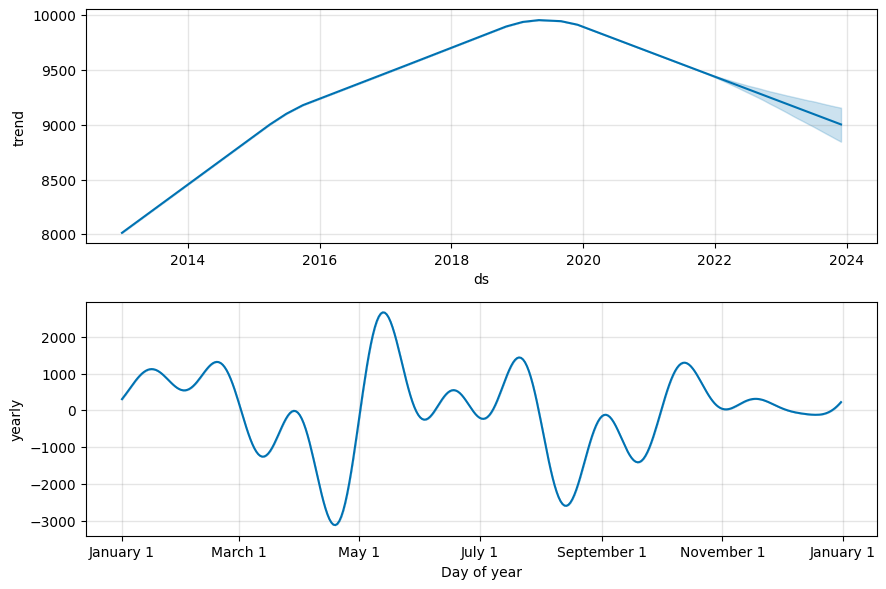

In [18]:
# Plot utama
model.plot(forecast)
plt.title('Forecast Harga (Prophet)')
plt.xlabel('Tanggal')
plt.ylabel('Price')
plt.show()

# Komponen tren dan musiman
model.plot_components(forecast)
plt.show()


In [19]:
# Pastikan kolom tanggal di kedua dataframe sama formatnya
forecast['ds'] = pd.to_datetime(forecast['ds'])
test['ds'] = pd.to_datetime(test['ds'])

# Gabungkan berdasarkan tanggal terdekat (opsi paling aman)
merged = pd.merge_asof(
    test.sort_values('ds'),
    forecast[['ds', 'yhat']],
    on='ds',
    direction='nearest'
)

# Evaluasi

mae = mean_absolute_error(merged['y'], merged['yhat'])
rmse = np.sqrt(mean_squared_error(merged['y'], merged['yhat']))
mape = np.mean(np.abs((merged['y'] - merged['yhat']) / merged['y'])) * 100
me = np.mean(merged['y'] - merged['yhat'])

print(f"ME   : {me:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MAPE : {mape:.2f}%")


ME   : 1365.63
RMSE : 1849.05
MAE  : 1381.66
MAPE : 12.07%


/tmp/ipython-input-2171263581.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test['ds'] = pd.to_datetime(test['ds'])
